# 07 — Diagnostik Model: Overfitting, Underfitting, dan Kebocoran Data

Notebook ini memeriksa apakah model terbaik tiap skenario (dari notebook 03) **pas**: tidak overfitting, tidak underfitting, dan tidak tertolong kebocoran data.

Semua analisis memakai **data latih saja** (457 foto asli, Opsi A) dengan fold validasi silang yang sama seperti notebook 03, kecuali pemeriksaan split di bagian 4 yang hanya mencocokkan daftar file. Tidak ada hyperparameter yang diubah; hasilnya bersifat diagnosis.

Cara membaca:

| Pola | Artinya |
|---|---|
| Skor latih tinggi, skor validasi jauh lebih rendah | **Overfitting** (varian tinggi): model menghafal data latih |
| Skor latih dan validasi sama-sama rendah | **Underfitting** (bias tinggi): model terlalu sederhana |
| Keduanya tinggi dan berdekatan | Pas |

SVM tidak punya kurva *loss* per *epoch*, jadi yang dipakai adalah **learning curve** (skor vs jumlah data latih) dan **validation curve** (skor vs hyperparameter).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
t0 = time.time()

import ast, hashlib
from sklearn.model_selection import (StratifiedGroupKFold, learning_curve, validation_curve,
                                     permutation_test_score, cross_validate)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from src.features import scenario_columns

warnings.filterwarnings("ignore", category=UserWarning)
FIG_DIR = config.FIGURES_DIR / "07_diagnostik"
FIG_DIR.mkdir(parents=True, exist_ok=True)
feats = pd.read_csv(config.FEATURES_DIR / "features_train.csv")
SCEN = scenario_columns(feats.columns)
dA = feats[feats["aug_type"] == "original"].reset_index(drop=True)
y = dA["label"].to_numpy()
folds = list(StratifiedGroupKFold(n_splits=config.N_FOLDS, shuffle=True, random_state=config.SEED)
             .split(dA, y, dA["origin_id"]))

cvres = pd.read_csv(config.RESULTS_DIR / "cv_results.csv")
cvres["best_params"] = cvres["best_params"].apply(ast.literal_eval)
best = cvres[cvres["best_in_scenario"]].set_index("scenario").loc[list(SCEN)]

def make_model(scen, **override):
    r = best.loc[scen]
    params = {**r["best_params"], **override}
    return Pipeline([("scaler", StandardScaler()),
                     ("svc", SVC(kernel=r["kernel"], class_weight="balanced"))]).set_params(
        **{f"svc__{k}": v for k, v in params.items()})

for s, r in best.iterrows():
    print(f"{s}: {r['kernel']} {r['best_params']}  (F1 CV {r['f1_macro_mean']:.3f} ± {r['f1_macro_std']:.3f})")

S1: rbf {'C': 100, 'gamma': 0.1}  (F1 CV 0.954 ± 0.007)
S2: linear {'C': 100}  (F1 CV 0.980 ± 0.011)
S3: rbf {'C': 100, 'gamma': 0.01}  (F1 CV 0.938 ± 0.033)
S4: linear {'C': 1}  (F1 CV 0.950 ± 0.013)


## 1. Selisih skor latih vs validasi (generalization gap)

Untuk tiap fold, model dilatih pada 4 fold lalu dinilai pada fold latihnya sendiri (skor latih) dan pada fold validasi. Selisih yang besar menandakan overfitting.

In [2]:
gap_rows = []
for s in SCEN:
    cvr = cross_validate(make_model(s), dA[SCEN[s]].to_numpy(), y, cv=folds,
                         scoring="f1_macro", return_train_score=True, n_jobs=-1)
    gap_rows.append({"skenario": s, "kernel": best.loc[s, "kernel"],
                     "F1 latih": cvr["train_score"].mean(), "F1 validasi": cvr["test_score"].mean(),
                     "std validasi": cvr["test_score"].std()})
gap = pd.DataFrame(gap_rows)
gap["selisih"] = gap["F1 latih"] - gap["F1 validasi"]
gap.round(3)

,skenario,kernel,F1 latih,F1 validasi,std validasi,selisih
0,S1,rbf,0.995,0.954,0.007,0.041
1,S2,linear,1.000,0.980,0.011,0.020
2,S3,rbf,1.000,0.938,0.033,0.062
3,S4,linear,1.000,0.950,0.013,0.050


## 2. Learning curve

Model dilatih dengan 20% sampai 100% data latih tiap fold. Subset diambil acak (`shuffle=True`, seed 42); tanpa pengacakan, subset kecil hanya berisi kelas-kelas pertama karena data tersusun per kelas.

- Kalau kurva validasi masih naik di ujung kanan, **menambah data** kemungkinan masih membantu.
- Kalau celah latih–validasi menyempit seiring bertambahnya data, model **belajar pola umum**, bukan menghafal.

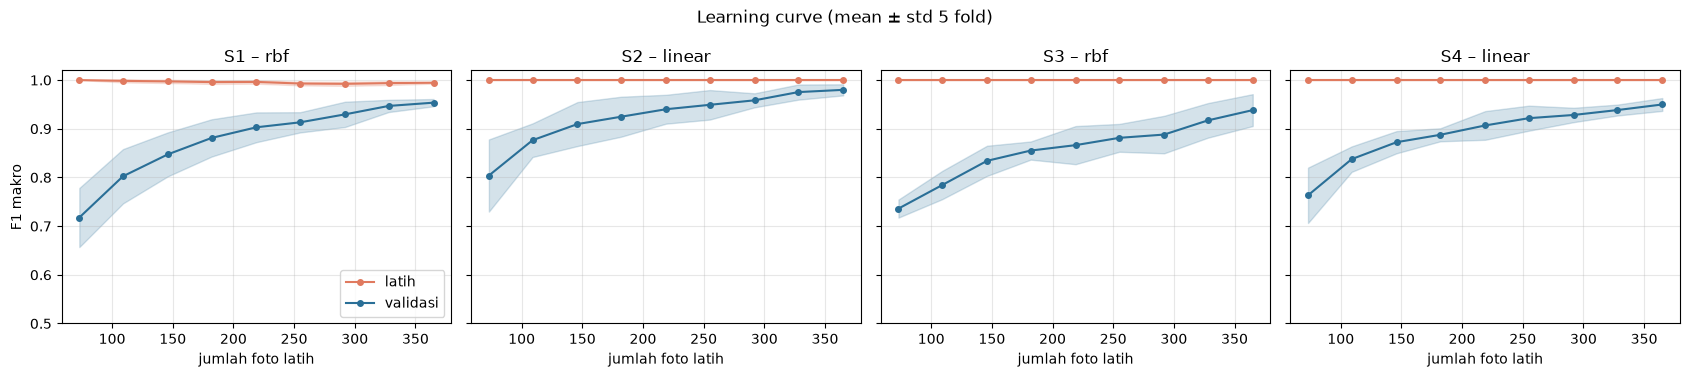

In [3]:
sizes_frac = np.linspace(0.2, 1.0, 9)
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8), sharey=True)
lc_rows = []
for ax, s in zip(axes, SCEN):
    n, tr, va = learning_curve(make_model(s), dA[SCEN[s]].to_numpy(), y, cv=folds,
                               train_sizes=sizes_frac, scoring="f1_macro",
                               shuffle=True, random_state=config.SEED, n_jobs=-1)
    for arr, lab, col in [(tr, "latih", "#e07a5f"), (va, "validasi", "#2a6f97")]:
        ax.plot(n, arr.mean(1), "o-", color=col, label=lab, ms=4)
        ax.fill_between(n, arr.mean(1) - arr.std(1), arr.mean(1) + arr.std(1), color=col, alpha=0.2)
    ax.set_title(f"{s} – {best.loc[s, 'kernel']}"); ax.set_xlabel("jumlah foto latih")
    ax.set_ylim(0.5, 1.02); ax.grid(alpha=0.3)
    lc_rows += [{"skenario": s, "n_latih": int(k), "F1 latih": a, "F1 validasi": b}
                for k, a, b in zip(n, tr.mean(1), va.mean(1))]
axes[0].set_ylabel("F1 makro"); axes[0].legend(loc="lower right")
fig.suptitle("Learning curve (mean ± std 5 fold)")
fig.tight_layout()
fig.savefig(FIG_DIR / "learning_curve.png", dpi=150)
plt.show()
lc = pd.DataFrame(lc_rows)

In [4]:
edge = lc.groupby("skenario").apply(lambda g: pd.Series({
    "F1 val (data terkecil)": g["F1 validasi"].iloc[0],
    "F1 val (data penuh)": g["F1 validasi"].iloc[-1],
    "naik di 2 titik terakhir": g["F1 validasi"].iloc[-1] - g["F1 validasi"].iloc[-3],
    "celah (data penuh)": g["F1 latih"].iloc[-1] - g["F1 validasi"].iloc[-1]}), include_groups=False)
edge.round(3)

,F1 val (data terkecil),F1 val (data penuh),naik di 2 titik terakhir,celah (data penuh)
skenario,,,,
S1,0.718,0.954,0.024,0.041
S2,0.804,0.980,0.021,0.020
S3,0.736,0.938,0.050,0.062
S4,0.763,0.950,0.022,0.050


## 3. Validation curve

Parameter **C** mengatur seberapa keras SVM menghukum kesalahan klasifikasi di data latih:

- C kecil → batas keputusan lebar dan "longgar" → cenderung **underfitting**;
- C besar → batas mengikuti data latih dengan ketat → berisiko **overfitting**.

Pada RBF, **gamma** mengatur jangkauan pengaruh tiap titik: gamma besar membuat batas sangat berliku (rawan overfitting). Kurva di bawah memakai rentang lebih lebar dari grid (C 10⁻³–10³) hanya untuk diagnosis; parameter terpilih ditandai garis putus-putus.

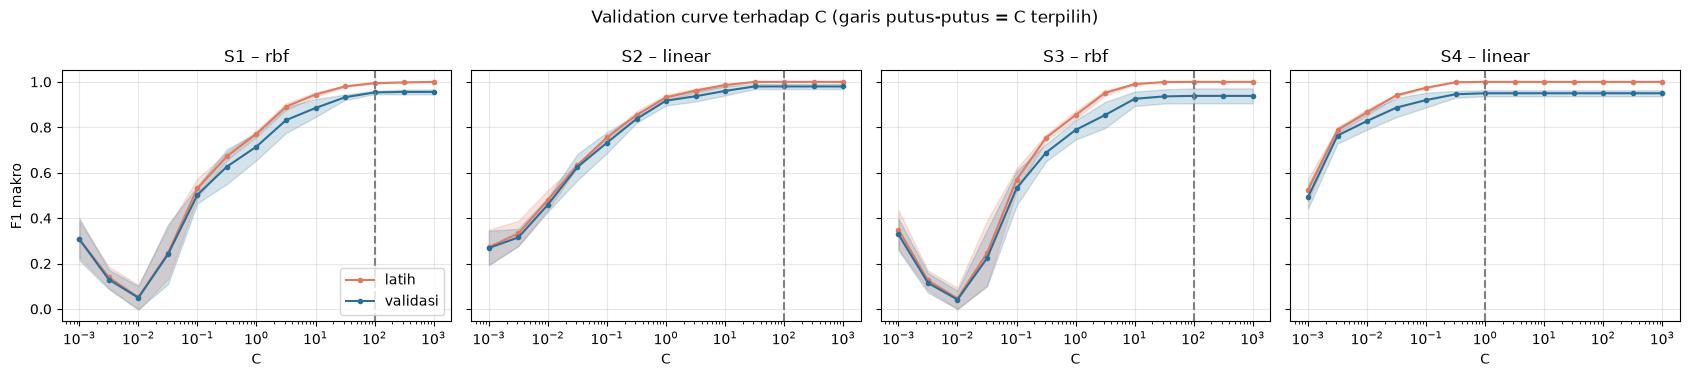

In [5]:
C_range = np.logspace(-3, 3, 13)
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8), sharey=True)
for ax, s in zip(axes, SCEN):
    tr, va = validation_curve(make_model(s), dA[SCEN[s]].to_numpy(), y, param_name="svc__C",
                              param_range=C_range, cv=folds, scoring="f1_macro", n_jobs=-1)
    for arr, lab, col in [(tr, "latih", "#e07a5f"), (va, "validasi", "#2a6f97")]:
        ax.semilogx(C_range, arr.mean(1), "o-", color=col, label=lab, ms=3)
        ax.fill_between(C_range, arr.mean(1) - arr.std(1), arr.mean(1) + arr.std(1), color=col, alpha=0.2)
    ax.axvline(best.loc[s, "best_params"]["C"], ls="--", color="gray")
    ax.set_title(f"{s} – {best.loc[s, 'kernel']}"); ax.set_xlabel("C"); ax.grid(alpha=0.3)
axes[0].set_ylabel("F1 makro"); axes[0].legend(loc="lower right")
fig.suptitle("Validation curve terhadap C (garis putus-putus = C terpilih)")
fig.tight_layout()
fig.savefig(FIG_DIR / "validation_curve_C.png", dpi=150)
plt.show()

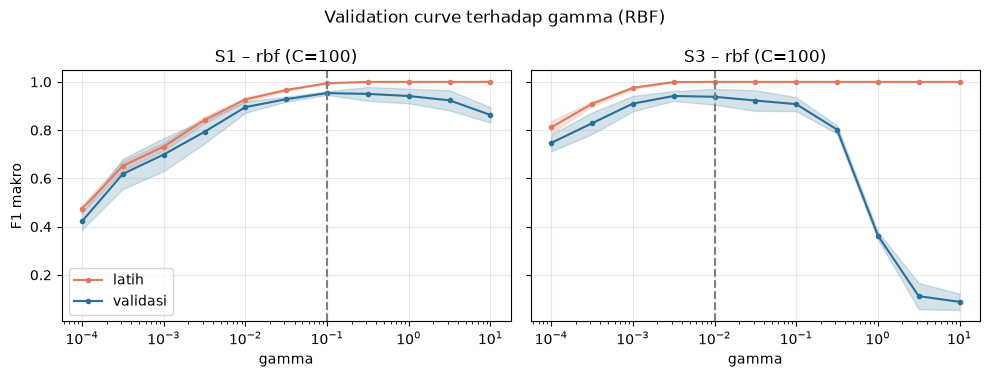

In [6]:
rbf_scen = [s for s in SCEN if best.loc[s, "kernel"] == "rbf"]
g_range = np.logspace(-4, 1, 11)
fig, axes = plt.subplots(1, len(rbf_scen), figsize=(5 * len(rbf_scen), 3.8), sharey=True, squeeze=False)
for ax, s in zip(axes[0], rbf_scen):
    tr, va = validation_curve(make_model(s), dA[SCEN[s]].to_numpy(), y, param_name="svc__gamma",
                              param_range=g_range, cv=folds, scoring="f1_macro", n_jobs=-1)
    for arr, lab, col in [(tr, "latih", "#e07a5f"), (va, "validasi", "#2a6f97")]:
        ax.semilogx(g_range, arr.mean(1), "o-", color=col, label=lab, ms=3)
        ax.fill_between(g_range, arr.mean(1) - arr.std(1), arr.mean(1) + arr.std(1), color=col, alpha=0.2)
    ax.axvline(best.loc[s, "best_params"]["gamma"], ls="--", color="gray")
    ax.set_title(f"{s} – rbf (C={best.loc[s, 'best_params']['C']})"); ax.set_xlabel("gamma"); ax.grid(alpha=0.3)
axes[0][0].set_ylabel("F1 makro"); axes[0][0].legend(loc="lower left")
fig.suptitle("Validation curve terhadap gamma (RBF)")
fig.tight_layout()
fig.savefig(FIG_DIR / "validation_curve_gamma.png", dpi=150)
plt.show()

## 4. Pemeriksaan kebocoran data

Kebocoran data (*data leakage*) terjadi kalau informasi dari data validasi/uji ikut masuk ke proses latih, sehingga skor terlihat lebih bagus daripada kenyataannya. Yang diperiksa:

1. **Split**: tidak ada `origin_id` di latih dan uji sekaligus, data uji hanya foto asli, dan salinan augmentasi foto uji tidak ada di data latih.
2. **File duplikat**: tidak ada file dengan isi identik (hash MD5 sama) yang tersebar di latih dan uji.
3. **Pipeline**: preprocessing dan fitur dihitung per citra (tanpa statistik seluruh dataset), dan `StandardScaler` berada di dalam `Pipeline` sehingga hanya di-*fit* pada fold latih.
4. **Permutation test**: label data latih diacak berkali-kali, lalu model dinilai dengan validasi silang yang sama. Kalau pipeline bocor, model tetap bisa mendapat skor tinggi meski labelnya acak. Kalau tidak bocor, skornya harus turun ke tingkat tebakan (sekitar 1/11 ≈ 0,09).
5. **Kebocoran kain** (temuan notebook 04): validasi silang ulang dengan fold per **blok nomor foto**, lihat bagian 5.

In [7]:
split = pd.read_csv(config.RESULTS_DIR / "split.csv")
tr_ids = set(split.loc[split["split"] == "train", "origin_id"])
te_ids = set(split.loc[split["split"] == "test", "origin_id"])
index = pd.read_csv(config.RESULTS_DIR / "dataset_index.csv")
aug_of_test_in_train = split[(split["split"] == "train") & split["origin_id"].isin(te_ids)]
checks = {
    "origin_id di latih & uji sekaligus": len(tr_ids & te_ids),
    "baris uji yang bukan foto asli": int((split.loc[split["split"] == "test", "aug_type"] != "original").sum()),
    "augmentasi foto uji yang ada di data latih": len(aug_of_test_in_train),
    "augmentasi foto uji yang dibuang (tidak dipakai sama sekali)": len(index) - len(split),
}
pd.Series(checks, name="jumlah").to_frame()

,jumlah
origin_id di latih & uji sekaligus,0
baris uji yang bukan foto asli,0
augmentasi foto uji yang ada di data latih,0
augmentasi foto uji yang dibuang (tidak dipakai sama sekali),920


In [8]:
def md5(fn):
    return hashlib.md5((config.RAW_DIR / fn).read_bytes()).hexdigest()

index["md5"] = [md5(fn) for fn in index["filename"]]
dup = index[index.duplicated("md5", keep=False)].sort_values("md5")
dup = dup.merge(split[["filename", "split"]], on="filename", how="left").fillna({"split": "dibuang"})
cross = dup.groupby("md5").filter(lambda g: g["origin_id"].nunique() > 1)
print(f"File dengan isi identik (hash sama): {len(dup)} file dalam {dup['md5'].nunique()} kelompok")
print(f"Kelompok identik yang melintasi origin_id berbeda: {cross['md5'].nunique()}")
if len(cross):
    print(cross[["filename", "split"]].head(10).to_string(index=False))

File dengan isi identik (hash sama): 387 file dalam 187 kelompok
Kelompok identik yang melintasi origin_id berbeda: 23
                                filename split
   Lumbon/Lumbon (27)_RandomRotate90.jpg train
   Lumbon/Lumbon (19)_RandomRotate90.jpg train
              Lumbon/Lumbon (25)_FDA.jpg train
              Lumbon/Lumbon (17)_FDA.jpg train
    Madu Bronto/Madu Bronto (42)_FDA.jpg train
    Madu Bronto/Madu Bronto (41)_FDA.jpg train
        Lumbon/Lumbon (18)_Transpose.jpg train
        Lumbon/Lumbon (26)_Transpose.jpg train
   Lumbon/Lumbon (25)_RandomRotate90.jpg train
Lumbon/Lumbon (25)_RandomGridShuffle.jpg train


### Foto asli yang identik

Sebagian besar kelompok identik di atas adalah augmentasi yang menghasilkan citra sama dengan augmentasi lain dari foto yang sama (misalnya rotasi dan pencerminan yang kebetulan setara). Itu bukan kebocoran. Yang perlu diperiksa adalah **foto asli** yang identik dengan foto asli bernomor lain: kalau pasangan seperti itu jatuh di fold latih dan fold validasi yang berbeda, model "melihat" foto validasi saat latihan.

In [9]:
orig = index[index["aug_type"] == "original"]
dup_orig = orig[orig.duplicated("md5", keep=False)].merge(split[["filename", "split"]], on="filename")
pairs = dup_orig.groupby("md5")["origin_id"].apply(lambda s: tuple(sorted(s)))
print(f"Foto asli identik: {len(dup_orig)} file = {len(pairs)} pasangan; split: {dup_orig['split'].value_counts().to_dict()}")

fold_of = {oid: k for k, (_, va) in enumerate(folds) for oid in dA["origin_id"].iloc[va]}
pair_tab = pd.DataFrame({"pasangan": [" = ".join(p) for p in pairs],
                         "fold di notebook 03": [tuple(fold_of.get(o) for o in p) for p in pairs]})
pair_tab["terpisah fold"] = pair_tab["fold di notebook 03"].apply(lambda t: len(set(t)) > 1)
pair_tab

Foto asli identik: 10 file = 5 pasangan; split: {'train': 10}


,pasangan,fold di notebook 03,terpisah fold
0,Madu Bronto_41 = Madu Bronto_42,"(3, 1)",True
1,Lumbon_17 = Lumbon_25,"(0, 4)",True
2,Lumbon_18 = Lumbon_26,"(4, 2)",True
3,Lumbon_24 = Lumbon_28,"(4, 2)",True
4,Lumbon_19 = Lumbon_27,"(3, 0)",True


In [10]:
# Re-run CV with each duplicate pair forced into the same group (hence the same fold)
merge_map = {o: p[0] for p in pairs for o in p}
groups_fixed = dA["origin_id"].map(lambda o: merge_map.get(o, o)).to_numpy()
folds_fixed = list(StratifiedGroupKFold(n_splits=config.N_FOLDS, shuffle=True, random_state=config.SEED)
                   .split(dA, y, groups_fixed))
dup_rows = []
for s in SCEN:
    X = dA[SCEN[s]].to_numpy()
    a = cross_validate(make_model(s), X, y, cv=folds, scoring="f1_macro", n_jobs=-1)["test_score"]
    b = cross_validate(make_model(s), X, y, cv=folds_fixed, scoring="f1_macro", n_jobs=-1)["test_score"]
    dup_rows.append({"skenario": s, "F1 fold notebook 03": f"{a.mean():.3f} ± {a.std():.3f}",
                     "F1 pasangan digabung": f"{b.mean():.3f} ± {b.std():.3f}", "selisih": round(a.mean() - b.mean(), 3)})
pd.DataFrame(dup_rows)

,skenario,F1 fold notebook 03,F1 pasangan digabung,selisih
0,S1,0.954 ± 0.007,0.961 ± 0.009,-0.008
1,S2,0.980 ± 0.011,0.989 ± 0.022,-0.009
2,S3,0.938 ± 0.033,0.940 ± 0.028,-0.002
3,S4,0.950 ± 0.013,0.949 ± 0.016,0.001


In [11]:
perm_rows = []
for s in SCEN:
    score, perm_scores, p = permutation_test_score(
        make_model(s), dA[SCEN[s]].to_numpy(), y, cv=folds, scoring="f1_macro",
        n_permutations=100, random_state=config.SEED, n_jobs=-1)
    perm_rows.append({"skenario": s, "F1 label asli": score, "F1 label acak (rata-rata)": perm_scores.mean(),
                      "F1 label acak (maks)": perm_scores.max(), "p-value": p})
perm = pd.DataFrame(perm_rows)
perm.round(3)

,skenario,F1 label asli,F1 label acak (rata-rata),F1 label acak (maks),p-value
0,S1,0.954,0.083,0.118,0.01
1,S2,0.980,0.081,0.121,0.01
2,S3,0.938,0.084,0.130,0.01
3,S4,0.950,0.085,0.119,0.01


p-value permutation test adalah proporsi pengacakan (ditambah 1) yang skornya ≥ skor label asli; dengan 100 pengacakan, nilai terkecil yang mungkin adalah 1/101 ≈ 0,0099.

## 5. Uji kebocoran kain: validasi silang per blok nomor foto

Notebook 04 menemukan bahwa foto uji hampir selalu punya foto latih dari kain yang sama, dengan nomor foto yang berdekatan. Dataset tidak punya label "ID kain", tetapi nomor foto bisa dipakai sebagai pendekatan: foto bernomor berdekatan cenderung berasal dari sesi pemotretan kain yang sama.

Di sini validasi silang diulang dengan fold berbasis **blok nomor foto**: nomor 1–13 jadi fold 0, 14–26 fold 1, 27–39 fold 2, 40–52 fold 3, untuk semua kelas. Dengan begitu, foto-foto bernomor berdekatan tidak bisa sekaligus ada di latih dan validasi (kecuali di batas blok). Hyperparameter tetap sama (dibekukan).

- Kalau skor **turun tajam** dibanding fold acak, akurasi tinggi selama ini sebagian besar berasal dari mengenali kain yang sama.
- Kalau skor **tetap tinggi**, model memang mengenali motif lintas sesi pemotretan.

In [12]:
block = ((dA["filename"].str.extract(r"\((\d+)\)")[0].astype(int) - 1) // 13).to_numpy()
block_folds = [(np.where(block != b)[0], np.where(block == b)[0]) for b in range(4)]
print("Ukuran fold blok (validasi):", [len(v) for _, v in block_folds])

blk_rows = []
for s in SCEN:
    X = dA[SCEN[s]].to_numpy()
    rnd = cross_validate(make_model(s), X, y, cv=folds, scoring="f1_macro", n_jobs=-1)["test_score"]
    blk = cross_validate(make_model(s), X, y, cv=block_folds, scoring="f1_macro", n_jobs=-1)["test_score"]
    blk_rows.append({"skenario": s, "kernel": best.loc[s, "kernel"],
                     "F1 fold acak": rnd.mean(), "std acak": rnd.std(),
                     "F1 fold blok": blk.mean(), "std blok": blk.std(),
                     "penurunan": rnd.mean() - blk.mean(),
                     **{f"blok {b}": v for b, v in enumerate(blk)}})
blk = pd.DataFrame(blk_rows)
blk.round(3)

Ukuran fold blok (validasi): [111, 119, 117, 110]


,skenario,kernel,F1 fold acak,std acak,F1 fold blok,std blok,penurunan,blok 0,blok 1,blok 2,blok 3
0,S1,rbf,0.954,0.007,0.764,0.108,0.190,0.790,0.874,0.808,0.584
1,S2,linear,0.980,0.011,0.821,0.102,0.159,0.850,0.911,0.876,0.648
2,S3,rbf,0.938,0.033,0.783,0.035,0.156,0.743,0.787,0.837,0.763
3,S4,linear,0.950,0.013,0.824,0.074,0.126,0.830,0.892,0.870,0.702


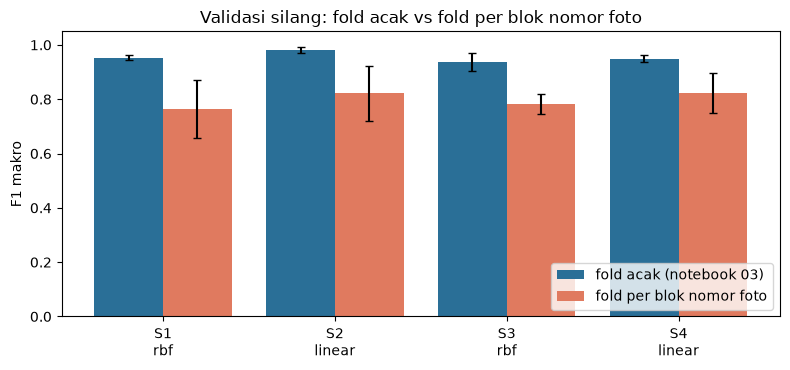

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(blk))
ax.bar(x - 0.2, blk["F1 fold acak"], 0.4, yerr=blk["std acak"], capsize=3, label="fold acak (notebook 03)", color="#2a6f97")
ax.bar(x + 0.2, blk["F1 fold blok"], 0.4, yerr=blk["std blok"], capsize=3, label="fold per blok nomor foto", color="#e07a5f")
ax.set_xticks(x, [f"{s}\n{k}" for s, k in zip(blk["skenario"], blk["kernel"])])
ax.set_ylabel("F1 makro"); ax.set_ylim(0, 1.05); ax.legend(loc="lower right")
ax.set_title("Validasi silang: fold acak vs fold per blok nomor foto")
fig.tight_layout()
fig.savefig(FIG_DIR / "cv_acak_vs_blok.png", dpi=150)
plt.show()

In [14]:
summary = gap.merge(perm[["skenario", "F1 label acak (rata-rata)", "p-value"]], on="skenario").merge(
    blk[["skenario", "F1 fold blok", "std blok", "penurunan"]], on="skenario")
summary.to_csv(config.RESULTS_DIR / "diagnostik_model.csv", index=False)
print("Disimpan: results/diagnostik_model.csv")

Disimpan: results/diagnostik_model.csv


## 6. Kesimpulan diagnostik

Semua angka berasal dari tabel-tabel di atas. Gambar learning/validation curve hanya dibaca secara kualitatif.

### Tidak underfitting

- Dengan data penuh, F1 validasi tinggi di semua skenario (0,938–0,980), dan skor latih mendekati 1.
- Pada validation curve terhadap C, skor latih dan validasi turun bersama-sama ketika C dikecilkan (paling tajam pada S1 dan S3 di C ≈ 0,01). Itu daerah underfitting: keduanya rendah dan berdekatan.
- C yang terpilih (1 atau 100) berada di daerah datar sebelah kanan, tempat skor validasi sudah maksimum. Jadi model terpilih **tidak underfitting**.

### Overfitting ringan, tetapi bukan karena hyperparameter

- **Selisih latih–validasi** pada model terbaik:

  | Model | Selisih F1 latih − validasi |
  |---|---|
  | S2 linear | 0,020 |
  | S1 RBF | 0,041 |
  | S4 linear | 0,050 |
  | S3 RBF | 0,062 |

  Skor latih hampir selalu 1,000. Itu wajar untuk SVM dengan C besar pada data kecil: semua titik latih bisa dipisahkan sempurna.
- **Validation curve:**
  - Terhadap C, skor validasi tidak turun saat C dinaikkan sampai 1000, jadi memperbesar C tidak memperburuk generalisasi.
  - Terhadap gamma (RBF), tampak jelas daerah overfitting: untuk gamma besar, skor latih tetap 1 tetapi skor validasi anjlok (sangat tajam pada S3).
  - Gamma yang terpilih (0,1 untuk S1 dan 0,01 untuk S3) berada di sekitar puncak skor validasi, **sebelum** daerah overfitting tersebut.
- **Learning curve:**
  - Skor validasi naik terus dari sekitar 0,72–0,80 (±73 foto latih) ke 0,94–0,98 (±365 foto latih), dan celahnya menyempit.
  - Di dua titik terakhir, skor validasi masih naik 0,021–0,050.
  - Artinya model belajar pola umum, dan **menambah data kemungkinan masih membantu**; kurvanya belum mendatar.

Kesimpulan: dengan hyperparameter terpilih, model berada di titik yang wajar, tidak underfitting dan tidak di daerah overfitting. Celah latih–validasi yang tersisa berasal dari jumlah data yang masih terbatas.

### Kebocoran data: tidak ada di pipeline, tetapi ada kebocoran kain

| Pemeriksaan | Hasil | Kesimpulan |
|---|---|---|
| `origin_id` di latih dan uji sekaligus | 0 | aman |
| Data uji berisi augmentasi | 0 | aman |
| Augmentasi foto uji di data latih | 0 (920 dibuang) | aman |
| Foto asli identik menyeberang latih ↔ uji | 0 (5 pasangan identik, semuanya di data latih) | aman untuk data uji |
| Dampak 5 pasangan identik pada CV | selisih −0,009 sampai +0,001, di dalam std | dapat diabaikan |
| Permutation test (label diacak 100×) | F1 turun ke ±0,08 (maks 0,130); p = 0,01, nilai terkecil yang mungkin | pipeline tidak bocor |
| CV per blok nomor foto | F1 turun 0,126–0,190 | **ada kebocoran kain** |

- **Pipeline bersih.**
  - Permutation test menunjukkan bahwa tanpa hubungan label–citra yang asli, model hanya mencapai tingkat tebakan (1/11 ≈ 0,09). Jadi tidak ada informasi label yang bocor lewat preprocessing, scaler, atau pemilihan fold.
  - Skor asli lebih tinggi daripada semua 100 skor acak.
- **Dataset memiliki 5 pasangan foto asli identik:** Lumbon 17 = 25, 18 = 26, 19 = 27, 24 = 28, dan Madu Bronto 41 = 42.
  - Kesepuluh file berada di data latih, jadi tidak menyentuh data uji.
  - Pada CV notebook 03, kelima pasangan jatuh di fold berbeda. Namun menggabungkannya hanya mengubah F1 sebesar −0,009 sampai +0,001, sehingga dampaknya tidak berarti.
  - Ini sebaiknya disebut di laporan sebagai catatan kualitas dataset: secara efektif, Lumbon hanya punya 48 foto unik dan Madu Bronto 51.
- **Kebocoran kain adalah masalah utamanya.**
  - Saat validasi silang memisahkan foto berdasarkan blok nomor foto (sehingga foto-foto berurutan dari sesi pemotretan yang sama tidak bisa berada di dua sisi), F1 turun cukup besar:

    | Model | F1 fold acak | F1 fold blok |
    |---|---|---|
    | S2 linear | 0,980 | 0,821 ± 0,102 |
    | S1 RBF | 0,954 | 0,764 ± 0,108 |
    | S3 RBF | 0,938 | 0,783 ± 0,035 |
    | S4 linear | 0,950 | 0,824 ± 0,074 |

  - Blok 3 (foto nomor 40–52) paling rendah untuk S1, S2, dan S4, sehingga kemungkinan kain atau sesi pemotretannya memang berbeda dari blok lain.
  - Ini mengonfirmasi temuan notebook 04: skor CV dan uji (0,94–1,00) **terlalu optimistis** untuk foto dari kain baru. Perkiraan yang lebih realistis ada di kisaran **0,76–0,82**.
  - Perkiraan ini pun masih kasar: blok nomor foto hanyalah pendekatan untuk "ID kain", karena label sebenarnya tidak tersedia.
- **Urutan skenario ikut berubah.** Dengan fold blok, S4 (0,824) dan S2 (0,821) praktis setara, disusul S3 (0,783) dan S1 (0,764). Semua selisih itu lebih kecil dari std blok (0,035–0,108), sehingga tidak meyakinkan.
  - Status H1–H3 di notebook 04 tetap dihitung dengan skema CV yang sudah ditetapkan di desain.
  - Hasil ini dicatat sebagai analisis sensitivitas: kesimpulan "S2 terbaik" tidak lagi tegas kalau kebocoran kain dikurangi.

### Ringkas

| Pertanyaan | Jawaban |
|---|---|
| Underfitting? | Tidak. |
| Overfitting? | Ringan dan wajar (skor latih ≈ 1, validasi 0,94–0,98). Hyperparameter terpilih tidak berada di daerah overfitting. |
| Kebocoran di pipeline (split, scaler, fitur)? | Tidak ada (permutation test, pemeriksaan split). |
| Kebocoran di dataset? | Ada dua. Pertama, 5 pasangan foto asli identik, yang dampaknya dapat diabaikan. Kedua, kain/sesi pemotretan yang sama di latih dan validasi/uji, yang dampaknya besar: F1 turun 0,13–0,19 bila dipisah per blok nomor foto. |

In [15]:
print(f"Waktu jalan notebook: {time.time() - t0:.0f} detik")

Waktu jalan notebook: 65 detik
